Plotting the processed data to visualize the steps.

Author: Tayler LaSharr

Date: September 2024

Read in libraries and the data we care about.

In [11]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import os
import re
from datetime import datetime

## define the directories for AZ and WY
base_dir = r'H:\My Drive\DroughtSurfing'
locations = ['WY', 'AZ', 'UT']
# locations = ['WY', 'UT']

## define file paths for the exported GeoTIFFs within each directory
ndvi_file_patterns = {
    'modis_ndvi': 'modis_ndvi.tif',  # single file
    'modis_ndvi_filtered': 'modis_ndvi_filtered.tif',  # single file
    'modis_ndvi_corrected': 'modis_ndvi_corrected_{}.tif',  # yearly files
    'smoothed_ndvi': 'smoothed_ndvi_{}.tif'  # yearly files
}
## get the years
years = range(2015, 2023 + 1)  # Modify this range based on your data


Functions for plotting.

In [12]:
## function to extract dates from the band names (assuming format: YYYY_MM_DD_NDVI)
def extract_dates(band_names):
    dates = []
    for name in band_names:
        
        ## extract the date part from the name using regex
        match = re.search(r'(\d{4}_\d{2}_\d{2})', name)
        if match:
            date_str = match.group(1)
            
            ## convert string to datetime object
            date_obj = datetime.strptime(date_str, '%Y_%m_%d')
            dates.append(date_obj)
    return dates

## function to read NDVI data and calculate the mean NDVI over time
def read_single_ndvi_file(ndvi_path):
    with rasterio.open(ndvi_path) as src:
        ndvi_data = src.read()  # Read all bands (layers) in the file
        band_names = src.descriptions  # Get band descriptions (dates)
        dates = extract_dates(band_names)
    return dates, ndvi_data

## function to read and stack NDVI that was saved yearly
def read_and_stack_ndvi_data(tiff_dir, file_pattern, years):
    stacked_ndvi = []
    dates = []

    for year in years:
        file_name = file_pattern.format(year)
        ndvi_path = os.path.join(tiff_dir, file_name)

        if os.path.exists(ndvi_path):
            with rasterio.open(ndvi_path) as src:
                ndvi_data = src.read()  ## read all bands (layers) in the file
                stacked_ndvi.append(ndvi_data)

                band_names = src.descriptions  ## get band descriptions (dates)
                dates.extend(extract_dates(band_names))

    ## stack all the NDVI arrays along the first dimension (time)
    if stacked_ndvi:
        stacked_ndvi = np.concatenate(stacked_ndvi, axis=0)
    
    return dates, stacked_ndvi

## function to calculate mean NDVI over time for each stack
def calculate_mean_ndvi(ndvi_stack):
    return [np.nanmean(ndvi_stack[i, :, :]) for i in range(ndvi_stack.shape[0])]



Plot the figures (both the unscaled and scaled)

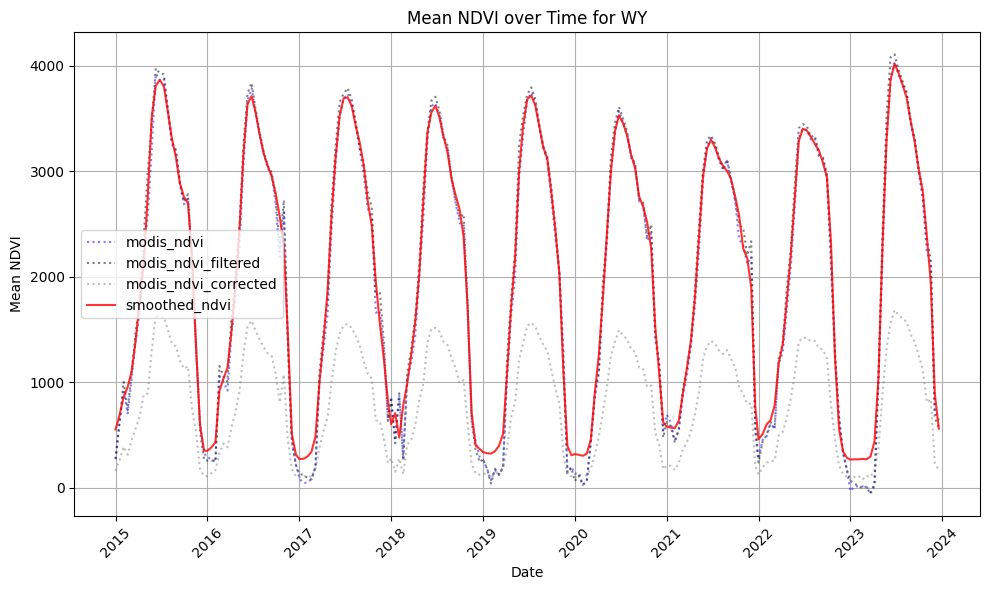

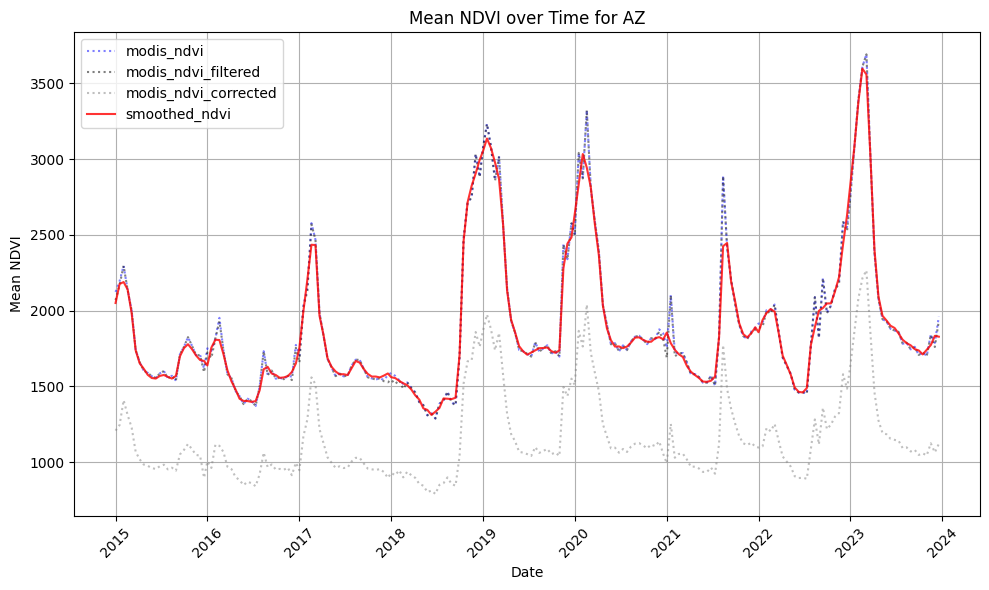

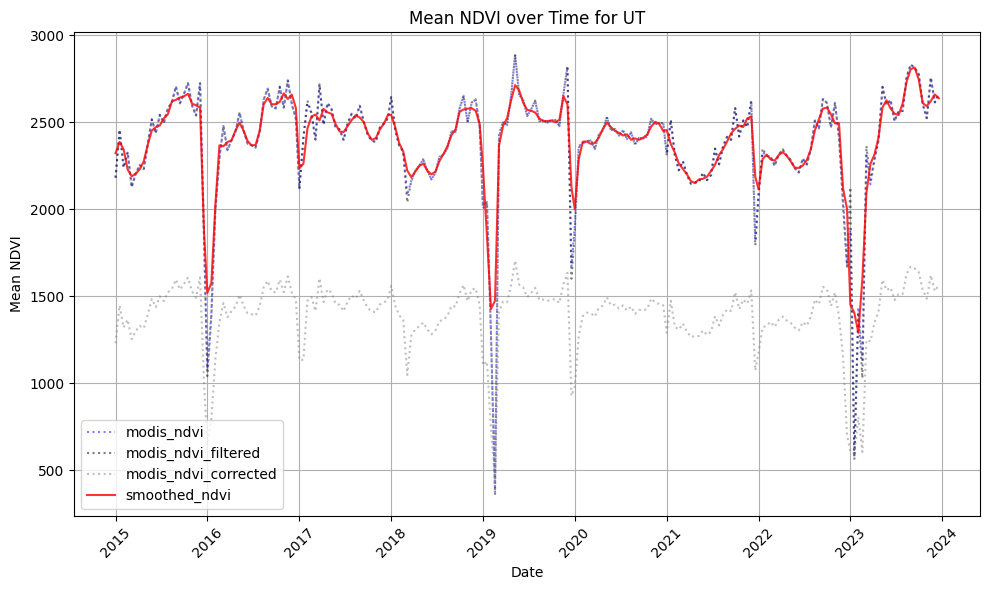

In [13]:
def plot_ndvi_over_time(locations, file_patterns, years, base_dir):
    for location in locations:
        plt.figure(figsize=(10, 6))
        tiff_dir = os.path.join(base_dir, location)

        # Define colors and line styles for different NDVI products
        styles = [':', ':', ':', '-']
        colors = ['blue', 'black', 'gray', 'red']
        alphas = [0.5, 0.5, 0.5, 0.8]

        for i, (label, file_pattern) in enumerate(file_patterns.items()):
            if 'corrected' in label or 'smoothed' in label:
                # For 'modis_ndvi_corrected' and 'smoothed_ndvi', we stack yearly files
                dates, stacked_ndvi = read_and_stack_ndvi_data(tiff_dir, file_pattern, years)
            else:
                # For 'modis_ndvi' and 'modis_ndvi_filtered', we read a single .tif file
                ndvi_path = os.path.join(tiff_dir, file_pattern)
                dates, stacked_ndvi = read_single_ndvi_file(ndvi_path)

            # Calculate mean NDVI for each time step
            mean_ndvi = calculate_mean_ndvi(stacked_ndvi)

            # Plot NDVI for each product
            plt.plot(dates, mean_ndvi, label=label, linestyle=styles[i], color=colors[i], alpha=alphas[i])

        # Add labels, title, and grid for each location
        plt.title(f'Mean NDVI over Time for {location}')
        plt.xlabel('Date')
        plt.ylabel('Mean NDVI')
        plt.legend(loc='best')
        plt.grid(True)
        plt.xticks(rotation=45)
        plt.tight_layout()

        # Show each plot separately
        plt.show()

# Call the function to plot the NDVI over time for each location
plot_ndvi_over_time(locations, ndvi_file_patterns, years, base_dir)

In [14]:
# Check the mean and range of NDVI values for each dataset
for label, file_pattern in ndvi_file_patterns.items():
    print(f"Processing {label}...")
    
    if 'corrected' in label or 'smoothed' in label:
        dates, stacked_ndvi = read_and_stack_ndvi_data(base_dir, file_pattern, years)
    else:
        ndvi_path = os.path.join(base_dir, file_pattern)
        dates, stacked_ndvi = read_single_ndvi_file(ndvi_path)
    
    # Calculate mean, min, and max NDVI for each stack
    mean_ndvi = calculate_mean_ndvi(stacked_ndvi)
    min_ndvi = np.nanmin(stacked_ndvi)
    max_ndvi = np.nanmax(stacked_ndvi)

    print(f"Mean NDVI for {label}: {np.mean(mean_ndvi)}")
    print(f"NDVI range for {label}: Min={min_ndvi}, Max={max_ndvi}")

Processing modis_ndvi...


RasterioIOError: H:/My Drive/DroughtSurfing/modis_ndvi.tif: No such file or directory